<a href="https://colab.research.google.com/github/AndreaFreemanfse/Aviation-Analysis/blob/main/play_store_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


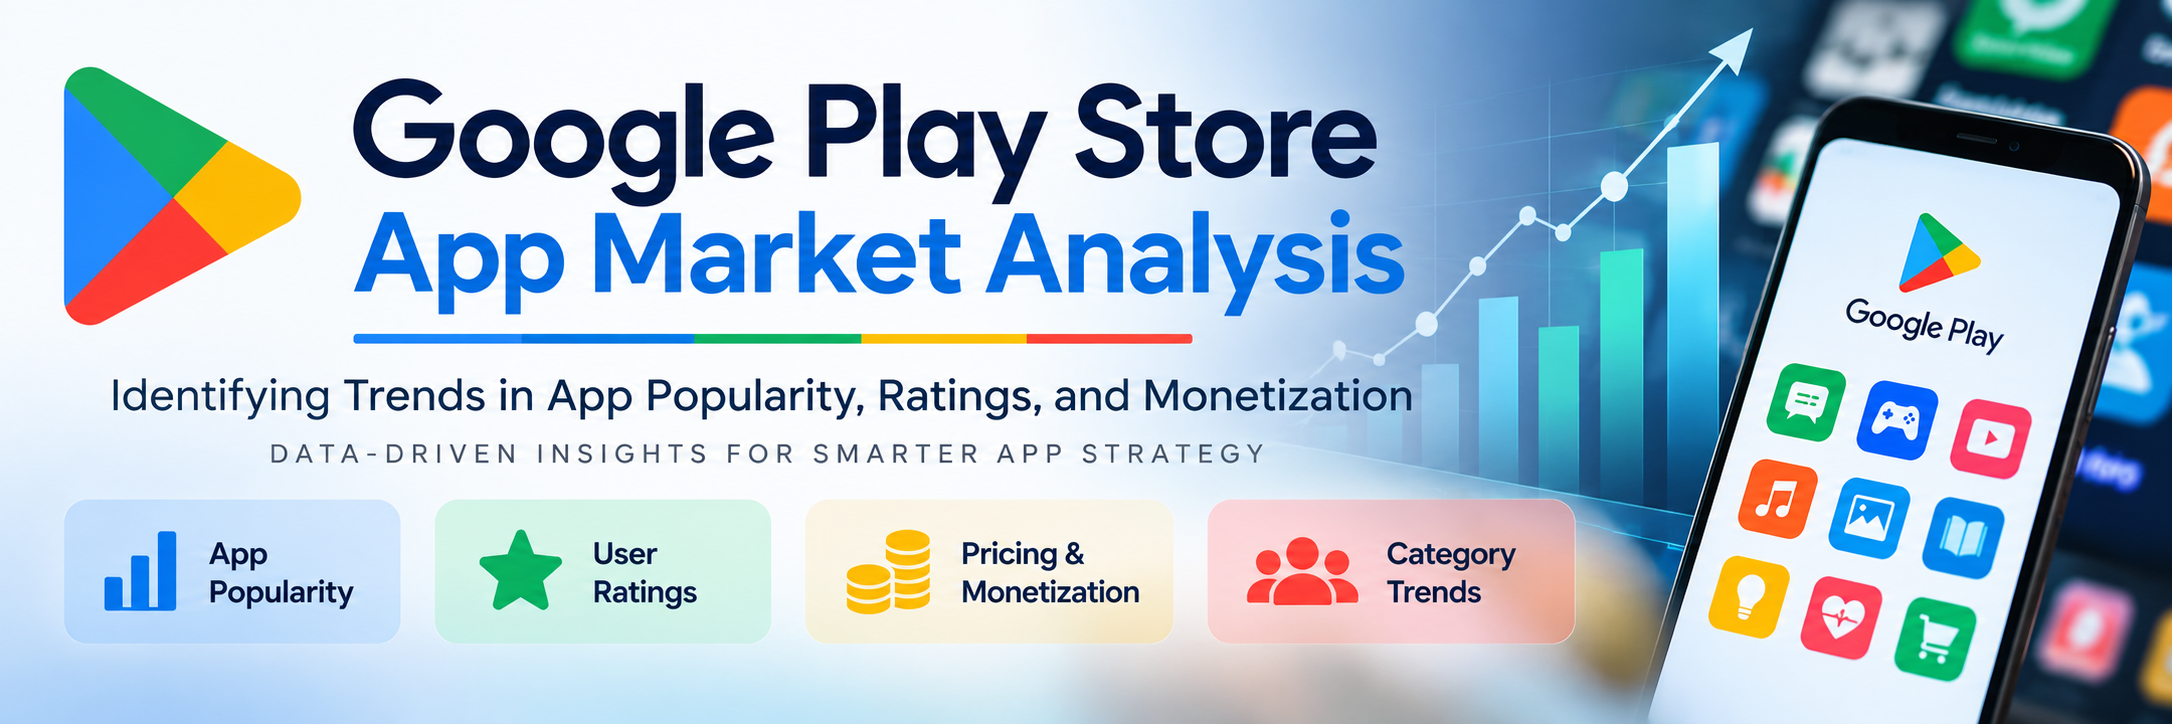

# Google Play Store App Market Analysis

## Overview
- BLUF (Bottom Line Up Front)

  The goal of this analysis is to identify app categories and characteristics that may offer promising opportunities for a new entrant into the Google Play Store market. By examining popularity, user satisfaction, and pricing patterns, the startup can make more evidence-based decisions about its initial app concept and monetization strategy. These metrics indicate potential market opportunities but do not independently establish profitability or guarantee success.

- One paragraph summary of findings and analysis

  The analysis examines relationships between app category, installs, ratings, reviews, and pricing to understand how performance varies across the Google Play Store. Data cleaning and validation help ensure that the resulting visualizations are reliable and interpretable. An interactive Tableau dashboard will present key metrics and comparisons, allowing stakeholders to explore market trends and identify areas for further investigation. Final recommendations will be based on the observed results rather than assumptions about which categories or business models will succeed.

- Frame your 'story'

  The central question is: What can existing Google Play Store app data tell us about opportunities for a startup entering the Android app market?

  The analysis will progress from understanding the overall market to comparing app categories, evaluating indicators of popularity and user satisfaction, and exploring differences between free and paid apps. The dashboard will translate these findings into accessible visual insights that support strategic decision-making.

## Business Understanding
- Set the stage for analysis
- Why are these findings relevant/important?
- Introduce stakeholders
- Postulate about questions you want to ask/answer

## Data Understanding
- Present the source of data
- Describe the data available
- What is relevant to keep what is not
- Present any data cleaning that needs to happen
- Null values? Type mismatches? Duplicates?

In [ ]:
# Imports
from pyspark.sql import SparkSession
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create a Spark session
spark = SparkSession.builder \
    .appName("App Store Analysis") \
    .getOrCreate()

# Verify Session is running
if (spark.getActiveSession()):
    print('yes')
else:
    print('no')

# Load in Data
from google.colab import drive
drive.mount('/content/drive')
db_path1 = "/content/drive/MyDrive/Colab Notebooks/summative_final/google_play_store_dataset.csv"


yes
Mounted at /content/drive


In [ ]:
# EDA Code Here - Load in Code

# Load the dataset into a PySpark DataFrame
spark_df = spark.read.csv(db_path1, header=True, inferSchema=True)

# Load to Pandas
df_pandas = spark_df.toPandas()

In [ ]:
# EDA Code Here - Investigate Data

# Display schema and first few rows
spark_df.printSchema()
spark_df.show(5)

root
 |-- App: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Rating: string (nullable = true)
 |-- Reviews: string (nullable = true)
 |-- Size: string (nullable = true)
 |-- Installs: string (nullable = true)
 |-- Type: string (nullable = true)
 |-- Price: string (nullable = true)
 |-- Content Rating: string (nullable = true)
 |-- Genres: string (nullable = true)
 |-- Last Updated: string (nullable = true)
 |-- Current Ver: string (nullable = true)
 |-- Android Ver: string (nullable = true)

+--------------------+--------------+------+-------+----+-----------+----+-----+--------------+--------------------+----------------+------------------+------------+
|                 App|      Category|Rating|Reviews|Size|   Installs|Type|Price|Content Rating|              Genres|    Last Updated|       Current Ver| Android Ver|
+--------------------+--------------+------+-------+----+-----------+----+-----+--------------+--------------------+----------------+--------------

## Data Preparation



I utilized ChatGpt to initiate data cleaning. Prompts and results included below:


# Data Cleaning Prompt:
    Act as an experienced data engineer and data analyst. Help me develop a professional, well-documented data cleaning pipeline for the Google Play Store dataset using PySpark and Pandas in Google Colab.

    Current Setup
    I have already loaded the dataset into a PySpark DataFrame and converted it to a Pandas DataFrame like so:

    Load the dataset into a PySpark DataFrame
    spark_df = spark.read.csv(db_path1, header=True, inferSchema=True)

    Convert to Pandas
    df_pandas = spark_df.toPandas()


    Objectives

    Assess data quality: Identify missing values, duplicate records, malformed rows, inconsistent formatting, incorrect data types, and invalid values.

    Clean the dataset: Recommend and implement appropriate handling for missing values, duplicates, ratings outside the valid 1–5 range, app sizes, prices, install counts, review counts, and dates.

    Preserve data integrity: Avoid unnecessarily deleting records or replacing missing values with misleading defaults. Explain the reasoning behind each cleaning decision.

    Use appropriate tools: Explain which operations should be performed in PySpark and which can be performed in Pandas. Since the dataset is already available in both formats, recommend an efficient workflow that avoids unnecessary conversions.

    Prevent and troubleshoot errors: Provide executable, step-by-step code that accounts for mixed data types, nonnumeric strings, malformed records, and missing values. Convert columns to appropriate data types before applying validation rules.

    Validate the results: Include checks for remaining duplicates, missing values, invalid ratings, negative prices or review counts, incorrect data types, and other relevant data-quality issues.

    Prepare for analysis: Explain how the cleaned dataset can support analysis of app popularity, user ratings, pricing, installs, app categories, and update history. Clearly distinguish available indicators from actual revenue or in-app purchase data that the dataset does not contain.

# Data Cleaning Prompt Result

    Since you've already loaded the Google Play Store dataset into a Pandas DataFrame, I'd recommend cleaning it in stages before analyzing app ratings, popularity, and monetization.

    I inspected your uploaded dataset: it contains 10,841 rows and 13 columns. The main issues I found are:

    Issue

    What I recommend

    Missing ratings

    Keep them as missing rather than assuming a rating of zero.

    Invalid values

    Ratings should be between 1 and 5; I found a malformed row with a rating of 19.0.

    Duplicate records

    Remove exact duplicate rows, but don't automatically remove every repeated app name.

    Incorrect data types

    Convert reviews, installs, prices, and dates to appropriate types.

    Inconsistent formatting

    Remove commas, currency symbols, and plus signs where appropriate.

    Missing app sizes

    Convert Varies with device to a missing value for numeric size analysis.

    Missing categorical values

    Investigate missing app types and content ratings; don't discard records unnecessarily.

In [ ]:
# Data Prep Code Here

# Data Cleaning Prompt Code :

# Make a copy so the original DataFrame stays unchanged
df_clean = df_pandas.copy()

# 1. Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# 2. Remove malformed rows with invalid category values
# Valid categories in this dataset use uppercase letters and underscores
valid_category = df_clean["Category"].astype(str).str.fullmatch(r"[A-Z_]+")
df_clean = df_clean[valid_category].copy()

# 3. Convert Reviews to numeric
df_clean["Reviews"] = pd.to_numeric(
    df_clean["Reviews"], errors="coerce"
)

# 4. Clean and convert Installs to numeric
df_clean["Installs"] = pd.to_numeric(
    df_clean["Installs"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.replace("+", "", regex=False),
    errors="coerce"
)

# 5. Clean and convert Price to numeric
df_clean["Price"] = pd.to_numeric(
    df_clean["Price"]
        .astype(str)
        .str.replace("$", "", regex=False),
    errors="coerce"
)

# 6. Convert ratings to numeric, then validate the range
df_clean["Rating"] = pd.to_numeric(
    df_clean["Rating"], errors="coerce"
)

# Ratings must be between 1 and 5
df_clean.loc[
    ~df_clean["Rating"].between(1, 5) & df_clean["Rating"].notna(),
    "Rating"
] = np.nan

# 7. Convert app size to megabytes
def convert_size(size):
    size = str(size).strip()

    if size in ("nan", "Varies with device"):
        return np.nan

    try:
        if size.endswith("M"):
            return float(size[:-1])
        elif size.endswith("k"):
            return float(size[:-1]) / 1024
        return np.nan
    except ValueError:
        return np.nan

df_clean["Size_MB"] = df_clean["Size"].apply(convert_size)

# 8. Convert Last Updated to datetime
df_clean["Last Updated"] = pd.to_datetime(
    df_clean["Last Updated"], errors="coerce"
)

# 9. Handle missing app type using price as a fallback
df_clean["Type"] = df_clean["Type"].fillna(
    df_clean["Price"].map(
        lambda price: "Free" if price == 0 else (
            "Paid" if pd.notna(price) else np.nan
        )
    )
)

# 10. Fill missing content ratings with an explicit label
df_clean["Content Rating"] = df_clean["Content Rating"].fillna("Unknown")

# Review the cleaned dataset
print("Cleaned shape:", df_clean.shape)
print("\nMissing values:")
print(df_clean.isna().sum().sort_values(ascending=False))

print("\nData types:")
print(df_clean.dtypes)

df_clean.head()

Cleaned shape: (10355, 14)

Missing values:
Size_MB           1525
Rating            1465
Current Ver          1
Reviews              0
Category             0
App                  0
Installs             0
Size                 0
Type                 0
Price                0
Genres               0
Content Rating       0
Last Updated         0
Android Ver          0
dtype: int64

Data types:
App                       object
Category                  object
Rating                   float64
Reviews                    int64
Size                      object
Installs                   int64
Type                      object
Price                    float64
Content Rating            object
Genres                    object
Last Updated      datetime64[ns]
Current Ver               object
Android Ver               object
Size_MB                  float64
dtype: object


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,10000,Free,0.0,Everyone,Art & Design,2018-01-07,1.0.0,4.0.3 and up,19.0
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,500000,Free,0.0,Everyone,Art & Design;Pretend Play,2018-01-15,2.0.0,4.0.3 and up,14.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,5000000,Free,0.0,Everyone,Art & Design,2018-08-01,1.2.4,4.0.3 and up,8.7
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,50000000,Free,0.0,Teen,Art & Design,2018-06-08,Varies with device,4.2 and up,25.0
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,100000,Free,0.0,Everyone,Art & Design;Creativity,2018-06-20,1.1,4.4 and up,2.8


In [ ]:
# Check results

# Check for remaining exact duplicates
print("Exact duplicates:", df_clean.duplicated().sum())

# Check rating range
print("Minimum rating:", df_clean["Rating"].min())
print("Maximum rating:", df_clean["Rating"].max())

# Check for negative values
print("Negative prices:", (df_clean["Price"] < 0).sum())
print("Negative installs:", (df_clean["Installs"] < 0).sum())
print("Negative reviews:", (df_clean["Reviews"] < 0).sum())

# Review the most common app categories
print(df_clean["Category"].value_counts().head(10))

Exact duplicates: 0
Minimum rating: 1.0
Maximum rating: 5.0
Negative prices: 0
Negative installs: 0
Negative reviews: 0
Category
FAMILY             1943
GAME               1121
TOOLS               843
BUSINESS            427
MEDICAL             408
PRODUCTIVITY        407
PERSONALIZATION     388
LIFESTYLE           373
COMMUNICATION       366
FINANCE             360
Name: count, dtype: int64


In [ ]:
# Save cleaned data file for Tableau usage
output_path = "/content/drive/MyDrive/Colab Notebooks/summative_final/google_play_store_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print(f"Cleaned dataset saved to: {output_path}")
print(f"Dataset shape: {df_clean.shape}")

Cleaned dataset saved to: /content/drive/MyDrive/Colab Notebooks/summative_final/google_play_store_cleaned.csv
Dataset shape: (10355, 14)


### Link to Published Dashboard

https://public.tableau.com/app/profile/andrea.freeman1480/viz/GooglePlayStoreMarketAnalysis_17927230521800/Dashboard1?publish=yes

## Conclusion

The analysis provides a starting point for identifying potentially promising market segments. Install counts offer an indication of app popularity, while ratings and review activity provide additional context about user engagement and satisfaction. Comparing free and paid apps also helps illustrate how monetization models differ across the market. However, popularity and high ratings alone do not guarantee commercial success.

Recommendations: A startup entering the Android market should use these findings to narrow its initial category selection, investigate competing apps, and identify opportunities to meet underserved user needs. From the finding you can see that categories such as Game, communication, Social and Productivity are highly downloaded - however this also may represent saturation in these markets leading to increased competition. Suggested to look for niche opportunities that could present more opportunity for an application to take off. Also the concentration of paid apps flatlines at the $46.00 mark suggesting that an application should not exceed this amount. Not that there are a couple applications with 1000 downloads above this mark but they are niche (I am Rich apps) and more of a joke app created by German developer Armin Heinrich that cost a lot of money and offers no practical use.

Further filtering was included in each dashboard to allow for more insight into particular categories etc.